# Trích xuất đặc trưng — Seafar

Notebook này khảo sát bảng đặc trưng đã trích xuất cho **Seafar**. Đây là bước Feature Extraction/Validation; chưa tạo nhãn và chưa huấn luyện mô hình. Các công thức 30 candidate vẫn là định nghĩa vận hành chờ nhóm phê duyệt.

## 1. Giới thiệu và cấu trúc dữ liệu

Seafar là chuỗi IMU/GPS đã được chuẩn hóa. Roll/Pitch lưu theo độ; trường rate được giữ với cảnh báo mapping trục và nguồn phần cứng chưa xác minh.

Dữ liệu đầu vào là các segment Parquet đã qua pipeline tiền xử lý. Mỗi file thuộc một segment của một session; extractor xử lý từng file độc lập để không tạo cửa sổ qua ranh giới session/segment.

In [1]:
from pathlib import Path
import json
import sys
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "ml/features").is_dir())
sys.path.insert(0, str(ROOT))
from ml.features.extractor import extract_segment
from ml.features.spec import FEATURE_NAMES

with (ROOT / "ml/features/config.yaml").open(encoding="utf-8") as stream:
    feature_config = yaml.safe_load(stream)
summary = json.loads((ROOT / "ml/reports/features/feature_extraction_summary.json").read_text(encoding="utf-8"))
dataset = "seafar"
dataset_summary = summary["datasets"][dataset]
processed_root = ROOT / "ml/data/processed" / dataset
parquet_files = sorted(processed_root.glob("**/timeseries.parquet"))
feature_values = pd.read_parquet(ROOT / "ml/data/features" / dataset / "feature_values.parquet")
feature_metadata = pd.read_parquet(ROOT / "ml/data/features" / dataset / "feature_metadata.parquet")
print(f"Số segment Parquet: {len(parquet_files)}")
print(f"Số cửa sổ ứng viên: {len(feature_values):,}")
print(f"Số hàng metadata validity: {len(feature_metadata):,}")

Số segment Parquet: 24
Số cửa sổ ứng viên: 1,384
Số hàng metadata validity: 1,384


## 2. Khảo sát schema và chất lượng đầu vào

Bảng dưới mô tả một segment đại diện và provenance đi kèm. Các số liệu tổng hợp được đọc từ lần chạy thực tế của CLI; notebook không tự thay đổi dữ liệu.

In [2]:
representative_path = max(parquet_files, key=lambda path: path.stat().st_size)
representative = pd.read_parquet(representative_path)
provenance = json.loads(representative_path.with_name("provenance.json").read_text(encoding="utf-8"))
structure = pd.DataFrame({"Cột": representative.columns, "Kiểu dữ liệu": [str(dtype) for dtype in representative.dtypes]})
display(structure)
quality = pd.DataFrame([
    {"Chỉ tiêu": "Session", "Giá trị": representative["session_id"].iloc[0]},
    {"Chỉ tiêu": "Segment", "Giá trị": representative["segment_id"].iloc[0]},
    {"Chỉ tiêu": "Số mẫu segment đại diện", "Giá trị": len(representative)},
    {"Chỉ tiêu": "Thời lượng (giây)", "Giá trị": round(float(representative.time_seconds.iloc[-1] - representative.time_seconds.iloc[0]), 3)},
    {"Chỉ tiêu": "Sampling Rate gốc (Hz)", "Giá trị": provenance.get("original_sampling_hz")},
    {"Chỉ tiêu": "Sampling Rate đích (Hz)", "Giá trị": provenance.get("target_sampling_hz_effective")},
    {"Chỉ tiêu": "Nguồn timestamp", "Giá trị": provenance.get("timestamp_source")},
    {"Chỉ tiêu": "Số segment toàn nguồn", "Giá trị": dataset_summary["segments"]},
    {"Chỉ tiêu": "Số session toàn nguồn", "Giá trị": dataset_summary["sessions"]},
])
display(quality)
print("Cảnh báo provenance:", " | ".join(provenance.get("warnings", [])) or "Không có cảnh báo được lưu.")

,Cột,Kiểu dữ liệu
0,dataset_source,str
1,session_id,str
2,segment_id,str
3,time_seconds,float64
4,roll_deg,float32
5,pitch_deg,float32
6,gyro_x_rad_s,float32
7,gyro_y_rad_s,float32
8,yaw_deg,float32
9,accel_x_m_s2,float32


,Chỉ tiêu,Giá trị
0,Session,seafar_session_001
1,Segment,segment_002
2,Số mẫu segment đại diện,59921
3,Thời lượng (giây),5992.0
4,Sampling Rate gốc (Hz),10.00001
5,Sampling Rate đích (Hz),10.0
6,Nguồn timestamp,datetime Unix epoch milliseconds
7,Số segment toàn nguồn,24
8,Số session toàn nguồn,1


Cảnh báo provenance: Các trường rate có tên đơn vị rad/min; chưa tìm thấy tài liệu cảm biến xác nhận nguồn phần cứng, trục và quy ước dấu. | Giữ nguyên dấu; ánh xạ roll/pitch rate sang trục x/y chỉ là ánh xạ theo tên trường.


## 3. Phương pháp và minh họa phép tính

Extractor dùng cửa sổ trailing `(t-W,t]`, stride 10 giây, coverage tối thiểu 95%, không bù giá trị thiếu và không nối segment. Độ lệch chuẩn dùng population (`ddof=0`); quantile dùng Type-7. Các quy ước chu kỳ, epsilon và xu thế vẫn cần nhóm duyệt.

**Rà soát nhóm chu kỳ:** `roll_period_est_180` dùng `roll_deg` sau khi trừ mean của chính cửa sổ 180 giây; không dùng tín hiệu detrend. Lần rà soát cuối phát hiện extractor từng đảo thứ tự mảng Roll và timestamp; lỗi đã được sửa và dữ liệu được tính lại. Bảng dưới đây hiển thị các endpoint có period tính được từ chính segment đang khảo sát.

In [3]:
values_demo, metadata_demo, segment_demo = extract_segment(
    representative, provenance, feature_config["features"], expected_dataset=dataset
)
valid_demo = metadata_demo[metadata_demo["complete_30_feature_row"] == False].head(8)
display(values_demo.head(8).iloc[:, :9])
print(f"Candidate rows trong segment minh họa: {len(values_demo):,}; endpoint đủ 180 giây: {segment_demo['candidate_windows_180s']:,}")

,window_id,roll_rms_60,roll_std_60,roll_mean_60,roll_peak_to_peak_60,roll_abs_p95_60,roll_abs_max_60,roll_iqr_60,roll_diff_rms_60
0,seafar|seafar_session_001|segment_002|2698.800000,2.896986,0.125871,2.894250,0.49,3.0600,3.11,0.17,0.010513
1,seafar|seafar_session_001|segment_002|2708.800000,2.904275,0.127318,2.901483,0.49,3.0600,3.11,0.16,0.010709
2,seafar|seafar_session_001|segment_002|2718.800000,2.914864,0.110561,2.912767,0.45,3.0400,3.07,0.11,0.010880
3,seafar|seafar_session_001|segment_002|2728.800000,2.940314,0.065562,2.939583,0.33,3.0400,3.07,0.10,0.010223
4,seafar|seafar_session_001|segment_002|2738.800000,2.926476,0.074907,2.925517,0.37,3.0400,3.07,0.10,0.009840
5,seafar|seafar_session_001|segment_002|2748.800000,2.911928,0.083996,2.910717,0.41,3.0300,3.06,0.11,0.010091
6,seafar|seafar_session_001|segment_002|2758.800000,2.919661,0.092886,2.918183,0.48,3.0700,3.13,0.12,0.010000
7,seafar|seafar_session_001|segment_002|2768.800000,2.948077,0.120427,2.945617,0.57,3.1605,3.22,0.16,0.010239


Candidate rows trong segment minh họa: 594; endpoint đủ 180 giây: 582


In [4]:
period_columns = ["window_id", "roll_period_est_180", "roll_zero_crossings_180", "roll_period_cv_180"]
period_preview = values_demo[period_columns].dropna(subset=["roll_period_est_180"]).tail(5)
display(period_preview)

,window_id,roll_period_est_180,roll_zero_crossings_180,roll_period_cv_180
589,seafar|seafar_session_001|segment_002|8588.800000,5.133333,29.0,0.931685
590,seafar|seafar_session_001|segment_002|8598.800000,5.005521,31.0,1.138911
591,seafar|seafar_session_001|segment_002|8608.800000,5.001815,32.0,1.098536
592,seafar|seafar_session_001|segment_002|8618.800000,4.769046,30.0,1.072445
593,seafar|seafar_session_001|segment_002|8628.800000,5.004917,32.0,1.061849


## 4. Availability và thống kê validity

`VALID` nghĩa là tín hiệu, cửa sổ và phép tính đủ điều kiện; không đồng nghĩa feature đã được phê duyệt về khoa học hoặc mapping cảm biến.

In [5]:
status_rows = []
for feature, counts in dataset_summary["feature_status_counts"].items():
    status_rows.append({"Feature": feature, **counts})
status_table = pd.DataFrame(status_rows).set_index("Feature")
display(status_table)
subset_table = pd.DataFrame([
    {"Tập con": name, "Số hàng đủ điều kiện": count}
    for name, count in dataset_summary["complete_practical_subsets"].items()
])
display(subset_table)
print(f"Hàng đủ cả 30 feature: {dataset_summary['complete_30_feature_rows']:,}")
print("Giải thích gyro:", "Seafar có trường rate theo tên dữ liệu nguồn, nhưng nguồn gyro vật lý, mapping trục và quy ước dấu chưa được xác nhận; các feature gyro được đánh dấu UNVERIFIED_SIGNAL_MAPPING.")

,VALID,MISSING_SOURCE_SIGNAL,INSUFFICIENT_WINDOW,INVALID_INPUT,UNDEFINED_MATHEMATICALLY,UNVERIFIED_SIGNAL_MAPPING
Feature,,,,,,
roll_rms_60,1384,0,0,0,0,0
roll_std_60,1384,0,0,0,0,0
roll_mean_60,1384,0,0,0,0,0
roll_peak_to_peak_60,1384,0,0,0,0,0
roll_abs_p95_60,1384,0,0,0,0,0
roll_abs_max_60,1384,0,0,0,0,0
roll_iqr_60,1384,0,0,0,0,0
roll_diff_rms_60,1384,0,0,0,0,0
gyro_x_rms_60,0,0,0,0,0,1384


,Tập con,Số hàng đủ điều kiện
0,roll_only_60,1384
1,roll_pitch_angle_60,1384
2,offset_and_growth_180,1318
3,angle_only_23_without_gyro_or_period,1318


Hàng đủ cả 30 feature: 0
Giải thích gyro: Seafar có trường rate theo tên dữ liệu nguồn, nhưng nguồn gyro vật lý, mapping trục và quy ước dấu chưa được xác nhận; các feature gyro được đánh dấu UNVERIFIED_SIGNAL_MAPPING.


## 5. Phân bố feature thực tế

Các histogram chỉ dùng giá trị hữu hạn trong feature table. Đơn vị được quy định trong feature specification; khi so sánh giữa nguồn cần lưu ý sampling rate, đơn vị và mapping trục.

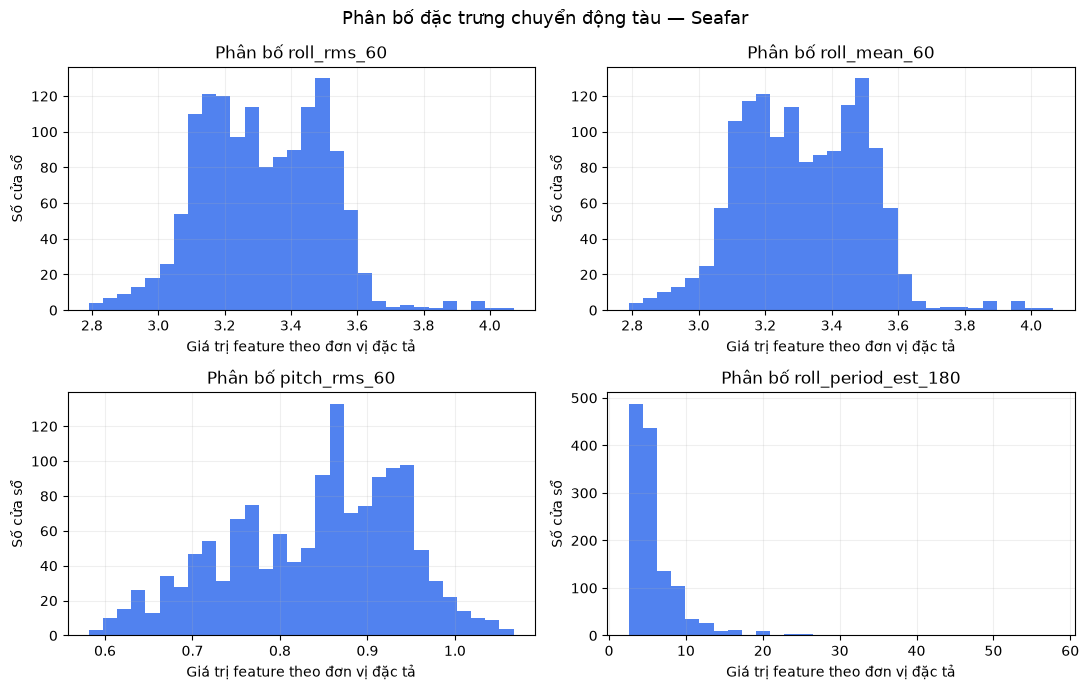

Đã lưu hình tại đường dẫn tương đối: ml/data/features/diagnostics/notebook_seafar_feature_distributions.png


In [6]:
plot_features = ["roll_rms_60", "roll_mean_60", "pitch_rms_60", "roll_period_est_180"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, feature in zip(axes.flat, plot_features):
    series = pd.to_numeric(feature_values[feature], errors="coerce").dropna()
    if len(series):
        ax.hist(series, bins=30, color="#2563eb", alpha=0.8)
    else:
        ax.text(0.5, 0.5, "Không có giá trị VALID", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"Phân bố {feature}")
    ax.set_xlabel("Giá trị feature theo đơn vị đặc tả")
    ax.set_ylabel("Số cửa sổ")
    ax.grid(True, alpha=0.2)
fig.suptitle("Phân bố đặc trưng chuyển động tàu — Seafar", fontsize=13)
fig.tight_layout()
figure_dir = ROOT / "ml/data/features/diagnostics"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_dir / "notebook_seafar_feature_distributions.png"
fig.savefig(figure_path, dpi=120)
plt.show()
print("Đã lưu hình tại đường dẫn tương đối:", figure_path.relative_to(ROOT))

## 6. Kiểm tra cửa sổ và giới hạn dữ liệu

Candidate row được tạo khi segment đã có đủ lịch sử 60 giây. Các feature 180 giây chỉ hợp lệ sau khi cùng segment tích lũy đủ 180 giây. Không ghép các session/run khác nhau để tăng thời lượng.

In [7]:
window_summary = pd.DataFrame([
    {"Chỉ tiêu": "Cửa sổ ứng viên 60 giây", "Số lượng": dataset_summary["candidate_windows_60s"]},
    {"Chỉ tiêu": "Endpoint có đủ lịch sử 180 giây", "Số lượng": dataset_summary["candidate_windows_180s"]},
    {"Chỉ tiêu": "Hàng có ít nhất một feature VALID", "Số lượng": dataset_summary["rows_with_any_valid_feature"]},
    {"Chỉ tiêu": "Hàng có INVALID_INPUT", "Số lượng": dataset_summary["invalid_input_rows"]},
    {"Chỉ tiêu": "Hàng đầy đủ 30 feature", "Số lượng": dataset_summary["complete_30_feature_rows"]},
])
display(window_summary)

,Chỉ tiêu,Số lượng
0,Cửa sổ ứng viên 60 giây,1384
1,Endpoint có đủ lịch sử 180 giây,1318
2,Hàng có ít nhất một feature VALID,1384
3,Hàng có INVALID_INPUT,0
4,Hàng đầy đủ 30 feature,0


## 7. Giải thích kỹ thuật phục vụ vấn đáp

- **Em đã làm gì?** Tính 30 candidate feature trên cửa sổ trailing theo từng segment Parquet.
- **Vì sao cần validity riêng?** Gyro có thể thiếu/chưa xác minh; cửa sổ ngắn hoặc có gap không được biểu diễn bằng số 0.
- **Phương pháp nào?** Thống kê population, Type-7, ba block 60 giây, hồi quy OLS và crossing zero nội suy tuyến tính theo định nghĩa vận hành.
- **Kết quả thực nghiệm?** Các bảng ở trên được nạp từ summary và Parquet thực tế sinh bởi CLI.
- **Rủi ro nếu bỏ qua ranh giới?** Cửa sổ có thể trộn hai thí nghiệm và tạo dữ liệu không tồn tại trong thực tế.
- **Giới hạn?** Các công thức còn chờ nhóm duyệt; mẫu 10 Hz và lọc baseline có thể ảnh hưởng feature chu kỳ/biên độ; gyro chưa đủ căn cứ để xem là tín hiệu canonical.